In [ ]:
import os
import re
import time
import enum


import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import git


import torch
from torch import nn
from torch.optim import Adam
from torchvision import transforms, datasets
from torchvision.utils import make_grid, save_image
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter

In [ ]:
BINARIES_PATH = os.path.join(os.getcwd(), 'models', 'binaries')
CHECKPOINTS_PATH = os.path.join(os.getcwd(), 'models', 'checkpoints')
DATA_DIR_PATH = os.path.join(os.getcwd(), 'data')
DEBUG_IMAGERY_PATH = os.path.join(DATA_DIR_PATH, 'debug_imagery')

MNIST_IMG_SIZE = 28

100%|██████████| 9.91M/9.91M [00:00<00:00, 43.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.15MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.3MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.08MB/s]


Dataset size: 60000 images.
Image shape torch.Size([1, 28, 28])


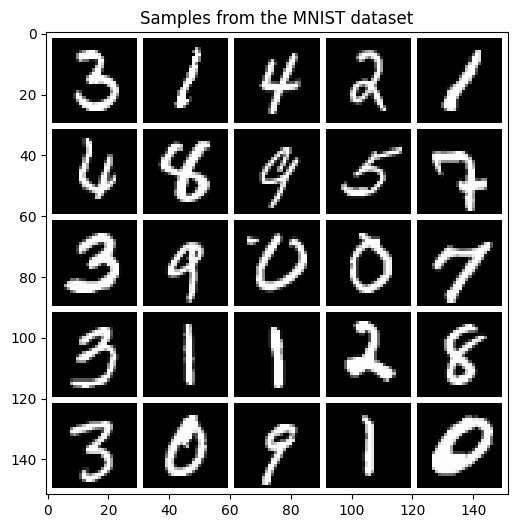

In [ ]:
batch_size = 128


transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((.5,), (.5,))
    ])


mnist_dataset = datasets.MNIST(root=DATA_DIR_PATH, train=True, download=True, transform=transform)


mnist_data_loader = DataLoader(mnist_dataset, batch_size=batch_size, shuffle=True, drop_last=True)


print(f'Dataset size: {len(mnist_dataset)} images.')

num_imgs_to_visualize = 25
batch = next(iter(mnist_data_loader))  # take a single batch from the dataset
img_batch = batch[0]  # extract only images and ignore the labels (batch[1])
img_batch_subset = img_batch[:num_imgs_to_visualize]  # extract only a subset of images

# Q2: What's the shape of my image?
# format is (B,C,H,W), B - number of images in batch, C - number of channels, H - height, W - width
print(f'Image shape {img_batch_subset.shape[1:]}')  # we ignore shape[0] - number of imgs in batch.

# Q3: How do my images look like?
# Creates a 5x5 grid of images, normalize will bring images from [-1, 1] range back into [0, 1] for display
# pad_value is 1. (white) because it's 0. (black) by default but since our background is also black,
# we wouldn't see the grid pattern so I set it to 1.
grid = make_grid(img_batch_subset, nrow=int(np.sqrt(num_imgs_to_visualize)), normalize=True, pad_value=1.)
grid = np.moveaxis(grid.numpy(), 0, 2)  # from CHW -> HWC format that's what matplotlib expects! Get used to this.
plt.figure(figsize=(6, 6))
plt.title("Samples from the MNIST dataset")
plt.imshow(grid)
plt.show()


In [ ]:
# Size of the generator's input vector. Generator will eventually learn how to map these into meaningful images!
LATENT_SPACE_DIM = 100


# This one will produce a batch of those vectors
def get_gaussian_latent_batch(batch_size, device):
    return torch.randn((batch_size, LATENT_SPACE_DIM), device=device)


# It's cleaner if you define the block like this - bear with me
def vanilla_block(in_feat, out_feat, normalize=True, activation=None):
    layers = [nn.Linear(in_feat, out_feat)]
    if normalize:
        layers.append(nn.BatchNorm1d(out_feat))
    # 0.2 was used in DCGAN, I experimented with other values like 0.5 didn't notice significant change
    layers.append(nn.LeakyReLU(0.2) if activation is None else activation)
    return layers


class GeneratorNet(torch.nn.Module):
    """Simple 4-layer MLP generative neural network.

    By default it works for MNIST size images (28x28).

    There are many ways you can construct generator to work on MNIST.
    Even without normalization layers it will work ok. Even with 5 layers it will work ok, etc.

    It's generally an open-research question on how to evaluate GANs i.e. quantify that "ok" statement.

    People tried to automate the task using IS (inception score, often used incorrectly), etc.
    but so far it always ends up with some form of visual inspection (human in the loop).

    Fancy way of saying you'll have to take a look at the images from your generator and say hey this looks good!

    """

    def __init__(self, img_shape=(MNIST_IMG_SIZE, MNIST_IMG_SIZE)):
        super().__init__()
        self.generated_img_shape = img_shape
        num_neurons_per_layer = [LATENT_SPACE_DIM, 256, 512, 1024, img_shape[0] * img_shape[1]]

        # Now you see why it's nice to define blocks - it's super concise!
        # These are pretty much just linear layers followed by LeakyReLU and batch normalization
        # Except for the last layer where we exclude batch normalization and we add Tanh (maps images into our [-1, 1] range!)
        self.net = nn.Sequential(
            *vanilla_block(num_neurons_per_layer[0], num_neurons_per_layer[1]),
            *vanilla_block(num_neurons_per_layer[1], num_neurons_per_layer[2]),
            *vanilla_block(num_neurons_per_layer[2], num_neurons_per_layer[3]),
            *vanilla_block(num_neurons_per_layer[3], num_neurons_per_layer[4], normalize=False, activation=nn.Tanh())
        )

    def forward(self, latent_vector_batch):
        img_batch_flattened = self.net(latent_vector_batch)
        # just un-flatten using view into (N, 1, 28, 28) shape for MNIST
        return img_batch_flattened.view(img_batch_flattened.shape[0], 1, *self.generated_img_shape)


# You can interpret the output from the discriminator as a probability and the question it should
# give an answer to is "hey is this image real?". If it outputs 1. it's 100% sure it's real. 0.5 - 50% sure, etc.
class DiscriminatorNet(torch.nn.Module):
    """Simple 3-layer MLP discriminative neural network. It should output probability 1. for real images and 0. for fakes.

    By default it works for MNIST size images (28x28).

    Again there are many ways you can construct discriminator network that would work on MNIST.
    You could use more or less layers, etc. Using normalization as in the DCGAN paper doesn't work well though.

    """

    def __init__(self, img_shape=(MNIST_IMG_SIZE, MNIST_IMG_SIZE)):
        super().__init__()
        num_neurons_per_layer = [img_shape[0] * img_shape[1], 512, 256, 1]

        # Last layer is Sigmoid function - basically the goal of the discriminator is to output 1.
        # for real images and 0. for fake images and sigmoid is clamped between 0 and 1 so it's perfect.
        self.net = nn.Sequential(
            *vanilla_block(num_neurons_per_layer[0], num_neurons_per_layer[1], normalize=False),
            *vanilla_block(num_neurons_per_layer[1], num_neurons_per_layer[2], normalize=False),
            *vanilla_block(num_neurons_per_layer[2], num_neurons_per_layer[3], normalize=False, activation=nn.Sigmoid())
        )

    def forward(self, img_batch):
        img_batch_flattened = img_batch.view(img_batch.shape[0], -1)  # flatten from (N,1,H,W) into (N, HxW)
        return self.net(img_batch_flattened)

In [ ]:
# Tried SGD for the discriminator, had problems tweaking it - Adam simply works nicely but default lr 1e-3 won't work!
# I had to train discriminator more (4 to 1 schedule worked) to get it working with default lr, still got worse results.
# 0.0002 and 0.5, 0.999 are from the DCGAN paper it works here nicely!
def get_optimizers(d_net, g_net):
    d_opt = Adam(d_net.parameters(), lr=0.0002, betas=(0.5, 0.999))
    g_opt = Adam(g_net.parameters(), lr=0.0002, betas=(0.5, 0.999))
    return d_opt, g_opt


# It's useful to add some metadata when saving your model, it should probably make sense to also add the number of epochs
def get_training_state(generator_net, gan_type_name):
    training_state = {
        "state_dict": generator_net.state_dict(),
        "gan_type": gan_type_name
    }
    return training_state


# Makes things useful when you have multiple models
class GANType(enum.Enum):
    VANILLA = 0


# Feel free to ignore this one not important for GAN training.
# It just figures out a good binary name so as not to overwrite your older models.
def get_available_binary_name(gan_type_enum=GANType.VANILLA):
    def valid_binary_name(binary_name):
        # First time you see raw f-string? Don't worry the only trick is to double the brackets.
        pattern = re.compile(rf'{gan_type_enum.name}_[0-9]{{6}}\.pth')
        return re.fullmatch(pattern, binary_name) is not None

    prefix = gan_type_enum.name
    # Just list the existing binaries so that we don't overwrite them but write to a new one
    valid_binary_names = list(filter(valid_binary_name, os.listdir(BINARIES_PATH)))
    if len(valid_binary_names) > 0:
        last_binary_name = sorted(valid_binary_names)[-1]
        new_suffix = int(last_binary_name.split('.')[0][-6:]) + 1  # increment by 1
        return f'{prefix}_{str(new_suffix).zfill(6)}.pth'
    else:
        return f'{prefix}_000000.pth'


In [ ]:
# For logging purpose
ref_batch_size = 16

discriminator_loss_values = []
generator_loss_values = []

img_cnt = 0

enable_tensorboard = True
console_log_freq = 50
debug_imagery_log_freq = 50
checkpoint_freq = 2

# For training purpose
num_epochs = 10  # feel free to increase this

########################################################

writer = SummaryWriter()  # (tensorboard) writer will output to ./runs/ directory by default

# Ensure directories exist
os.makedirs(DEBUG_IMAGERY_PATH, exist_ok=True)
os.makedirs(BINARIES_PATH, exist_ok=True)
os.makedirs(CHECKPOINTS_PATH, exist_ok=True)

# Hopefully you have some GPU ^^
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ref_noise_batch = get_gaussian_latent_batch(ref_batch_size, device)  # Track G's quality during training on fixed noise vectors

# Prepare feed-forward nets (place them on GPU if present) and optimizers which will tweak their weights
discriminator_net = DiscriminatorNet().train().to(device)
generator_net = GeneratorNet().train().to(device)

discriminator_opt, generator_opt = get_optimizers(discriminator_net, generator_net)

# 1s (real_images_gt) will configure BCELoss into -log(x) (check out the loss image above that's -log(x))
# whereas 0s (fake_images_gt) will configure it to -log(1-x)
# So that means we can effectively use binary cross-entropy loss to achieve adversarial loss!
adversarial_loss = nn.BCELoss()
real_images_gt = torch.ones((batch_size, 1), device=device)
fake_images_gt = torch.zeros((batch_size, 1), device=device)

ts = time.time()  # start measuring time

# GAN training loop, it's always smart to first train the discriminator so as to avoid mode collapse!
# A mode collapse, for example, is when your generator learns to only generate a single digit instead of all 10 digits!
for epoch in range(num_epochs):
    for batch_idx, (real_images, _) in enumerate(mnist_data_loader):

        real_images = real_images.to(device)  # Place imagery on GPU (if present)

        #
        # Train discriminator: maximize V = log(D(x)) + log(1-D(G(z))) or equivalently minimize -V
        # Note: D = discriminator, x = real images, G = generator, z = latent Gaussian vectors, G(z) = fake images
        #

        # Zero out .grad variables in discriminator network,
        # otherwise we would have corrupt results - leftover gradients from the previous training iteration
        discriminator_opt.zero_grad()

        # -log(D(x)) <- we minimize this by making D(x)/discriminator_net(real_images) as close to 1 as possible
        real_discriminator_loss = adversarial_loss(discriminator_net(real_images), real_images_gt)

        # G(z) | G == generator_net and z == get_gaussian_latent_batch(batch_size, device)
        fake_images = generator_net(get_gaussian_latent_batch(batch_size, device))
        # D(G(z)), we call detach() so that we don't calculate gradients for the generator during backward()
        fake_images_predictions = discriminator_net(fake_images.detach())
        # -log(1 - D(G(z))) <- we minimize this by making D(G(z)) as close to 0 as possible
        fake_discriminator_loss = adversarial_loss(fake_images_predictions, fake_images_gt)

        discriminator_loss = real_discriminator_loss + fake_discriminator_loss
        discriminator_loss.backward()  # this will populate .grad vars in the discriminator net
        discriminator_opt.step()  # perform D weights update according to optimizer's strategy

        #
        # Train generator: minimize V1 = log(1-D(G(z))) or equivalently maximize V2 = log(D(G(z))) (or min of -V2)
        # The original expression (V1) had problems with diminishing gradients for G when D is too good.
        #

        # if you want to cause mode collapse probably the easiest way to do that would be to add "for i in range(n)"
        # here (simply train G more frequent than D), n = 10 worked for me other values will also work - experiment.

        # Zero out .grad variables in discriminator network (otherwise we would have corrupt results)
        generator_opt.zero_grad()

        # D(G(z)) (see above for explanations)
        generated_images_predictions = discriminator_net(generator_net(get_gaussian_latent_batch(batch_size, device)))
        # By placing real_images_gt here we minimize -log(D(G(z))) which happens when D approaches 1
        # i.e. we're tricking D into thinking that these generated images are real!
        generator_loss = adversarial_loss(generated_images_predictions, real_images_gt)

        generator_loss.backward()  # this will populate .grad vars in the G net (also in D but we won't use those)
        generator_opt.step()  # perform G weights update according to optimizer's strategy

        #
        # Logging and checkpoint creation
        #

        generator_loss_values.append(generator_loss.item())
        discriminator_loss_values.append(discriminator_loss.item())

        if enable_tensorboard:
            global_batch_idx = len(mnist_data_loader) * epoch + batch_idx + 1
            writer.add_scalars('losses/g-and-d', {'g': generator_loss.item(), 'd': discriminator_loss.item()}, global_batch_idx)
            # Save debug imagery to tensorboard also (some redundancy but it may be more beginner-friendly)
            if batch_idx % debug_imagery_log_freq == 0:
                with torch.no_grad():
                    log_generated_images = generator_net(ref_noise_batch)
                    log_generated_images = nn.Upsample(scale_factor=2, mode='nearest')(log_generated_images)
                    intermediate_imagery_grid = make_grid(log_generated_images, nrow=int(np.sqrt(ref_batch_size)), normalize=True)
                    writer.add_image('intermediate generated imagery', intermediate_imagery_grid, global_batch_idx)

        if batch_idx % console_log_freq == 0:
            prefix = 'GAN training: time elapsed'
            print(f'{prefix} = {(time.time() - ts):.2f} [s] | epoch={epoch + 1} | batch= [{batch_idx + 1}/{len(mnist_data_loader)}]')

        # Save intermediate generator images (more convenient like this than through tensorboard)
        if batch_idx % debug_imagery_log_freq == 0:
            with torch.no_grad():
                log_generated_images = generator_net(ref_noise_batch)
                log_generated_images_resized = nn.Upsample(scale_factor=2.5, mode='nearest')(log_generated_images)
                out_path = os.path.join(DEBUG_IMAGERY_PATH, f'{str(img_cnt).zfill(6)}.jpg')
                save_image(log_generated_images_resized, out_path, nrow=int(np.sqrt(ref_batch_size)), normalize=True)
                img_cnt += 1

        # Save generator checkpoint
        if (epoch + 1) % checkpoint_freq == 0 and batch_idx == 0:
            ckpt_model_name = f"vanilla_ckpt_epoch_{epoch + 1}_batch_{batch_idx + 1}.pth"
            torch.save(get_training_state(generator_net, GANType.VANILLA.name), os.path.join(CHECKPOINTS_PATH, ckpt_model_name))

# Save the latest generator in the binaries directory
torch.save(get_training_state(generator_net, GANType.VANILLA.name), os.path.join(BINARIES_PATH, get_available_binary_name()))


GAN training: time elapsed = 0.12 [s] | epoch=1 | batch= [1/468]
GAN training: time elapsed = 4.52 [s] | epoch=1 | batch= [51/468]
GAN training: time elapsed = 9.79 [s] | epoch=1 | batch= [101/468]
GAN training: time elapsed = 18.65 [s] | epoch=1 | batch= [151/468]
GAN training: time elapsed = 23.24 [s] | epoch=1 | batch= [201/468]
GAN training: time elapsed = 27.49 [s] | epoch=1 | batch= [251/468]
GAN training: time elapsed = 33.50 [s] | epoch=1 | batch= [301/468]
GAN training: time elapsed = 38.23 [s] | epoch=1 | batch= [351/468]
GAN training: time elapsed = 43.22 [s] | epoch=1 | batch= [401/468]
GAN training: time elapsed = 49.04 [s] | epoch=1 | batch= [451/468]
GAN training: time elapsed = 50.51 [s] | epoch=2 | batch= [1/468]
GAN training: time elapsed = 54.79 [s] | epoch=2 | batch= [51/468]
GAN training: time elapsed = 60.60 [s] | epoch=2 | batch= [101/468]
GAN training: time elapsed = 65.39 [s] | epoch=2 | batch= [151/468]
GAN training: time elapsed = 69.53 [s] | epoch=2 | batch=

In [ ]:
def postprocess_generated_img(generated_img_tensor):
    assert isinstance(generated_img_tensor, torch.Tensor), f'Expected PyTorch tensor but got {type(generated_img_tensor)}.'

    # Move the tensor from GPU to CPU, convert to numpy array, extract 0th batch, move the image channel
    # from 0th to 2nd position (CHW -> HWC)
    generated_img = np.moveaxis(generated_img_tensor.to('cpu').numpy()[0], 0, 2)

    # Since MNIST images are grayscale (1-channel only) repeat 3 times to get RGB image
    generated_img = np.repeat(generated_img,  3, axis=2)

    # Imagery is in the range [-1, 1] (generator has tanh as the output activation) move it into [0, 1] range
    generated_img -= np.min(generated_img)
    generated_img /= np.max(generated_img)

    return generated_img


# This function will generate a random vector pass it to the generator which will generate a new image
# which we will just post-process and return it
def generate_from_random_latent_vector(generator):
    with torch.no_grad():  # Tells PyTorch not to compute gradients which would have huge memory footprint

        # Generate a single random (latent) vector
        latent_vector = get_gaussian_latent_batch(1, next(generator.parameters()).device)

        # Post process generator output (as it's in the [-1, 1] range, remember?)
        generated_img = postprocess_generated_img(generator(latent_vector))

    return generated_img


# You don't need to get deep into this one - irrelevant for GANs - it will just figure out a good name for your generated
# images so that you don't overwrite the old ones. They'll be stored with xxxxxx.jpg naming scheme.
def get_available_file_name(input_dir):
    def valid_frame_name(str):
        pattern = re.compile(r'[0-9]{6}\.jpg')  # regex, examples it covers: 000000.jpg or 923492.jpg, etc.
        return re.fullmatch(pattern, str) is not None

    # Filter out only images with xxxxxx.jpg format from the input_dir
    valid_frames = list(filter(valid_frame_name, os.listdir(input_dir)))
    if len(valid_frames) > 0:
        # Images are saved in the <xxxxxx>.jpg format we find the biggest such <xxxxxx> number and increment by 1
        last_img_name = sorted(valid_frames)[-1]
        new_prefix = int(last_img_name.split('.')[0]) + 1  # increment by 1
        return f'{str(new_prefix).zfill(6)}.jpg'
    else:
        return '000000.jpg'


def save_and_maybe_display_image(dump_dir, dump_img, out_res=(256, 256), should_display=False):
    assert isinstance(dump_img, np.ndarray), f'Expected numpy array got {type(dump_img)}.'

    # step1: get next valid image name
    dump_img_name = get_available_file_name(dump_dir)

    # step2: convert to uint8 format <- OpenCV expects it otherwise your image will be completely black. Don't ask...
    if dump_img.dtype != np.uint8:
        dump_img = (dump_img*255).astype(np.uint8)

    # step3: write image to the file system (::-1 because opencv expects BGR (and not RGB) format...)
    cv.imwrite(os.path.join(dump_dir, dump_img_name), cv.resize(dump_img[:, :, ::-1], out_res, interpolation=cv.INTER_NEAREST))

    # step4: maybe display part of the function
    if should_display:
        plt.imshow(dump_img)
        plt.show()

Model states contains this data: dict_keys(['state_dict', 'gan_type'])
Using VANILLA GAN!
Generating new MNIST-like images!


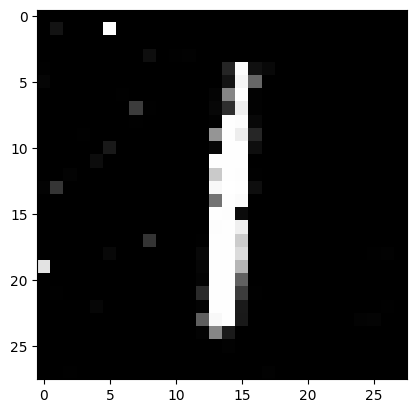

In [ ]:
# VANILLA_000000.pth is the model I pretrained for you, feel free to change it if you trained your own model (last section)!
model_path = os.path.join(BINARIES_PATH, 'VANILLA_000000.pth')
assert os.path.exists(model_path), f'Could not find the model {model_path}. You first need to train your generator.'

# Hopefully you have some GPU ^^
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# let's load the model, this is a dictionary containing model weights but also some metadata
# commit_hash - simply tells me which version of my code generated this model (hey you have to learn git!)
# gan_type - this one is "VANILLA" but I also have "DCGAN" and "cGAN" models
# state_dict - contains the actuall neural network weights
model_state = torch.load(model_path)
print(f'Model states contains this data: {model_state.keys()}')

gan_type = model_state["gan_type"]  #
print(f'Using {gan_type} GAN!')

# Let's instantiate a generator net and place it on GPU (if you have one)
generator = GeneratorNet().to(device)
# Load the weights, strict=True just makes sure that the architecture corresponds to the weights 100%
generator.load_state_dict(model_state["state_dict"], strict=True)
generator.eval()  # puts some layers like batch norm in a good state so it's ready for inference <- fancy name right?

generated_imgs_path = os.path.join(DATA_DIR_PATH, 'generated_imagery')  # this is where we'll dump images
os.makedirs(generated_imgs_path, exist_ok=True)

#
# This is where the magic happens!
#

print('Generating new MNIST-like images!')
generated_img = generate_from_random_latent_vector(generator)
save_and_maybe_display_image(generated_imgs_path, generated_img, should_display=True)